# WikiPulse — Revert prediction (machine learning)

**Question:** can information available *at the moment an edit is saved* predict whether it will later be reverted?

**Framing:** a possible *moderation-assistance signal* (which edits deserve a second look first) — **not** a vandalism
detector and not proof that an edit is bad. A missing `mw-reverted` tag means "no revert detected", not "good edit".

**Rules we follow**
1. Only edit-time features (`src/ml/features.py`); the label tag `mw-reverted` and any later-added tag are never used.
   Page creations are excluded: bad new pages are deleted, not reverted, so their label is always 0 (see EDA §8).
2. Chronological split: learn from the earliest 80 % of edits, test on the latest 20 %.
3. Report class imbalance; judge models by precision / recall / F1 / PR-AUC, not accuracy alone.
4. Fixed random seed (42): re-running gives the same numbers.

> Run this notebook top to bottom (Kernel → Restart & Run All). Training takes about a minute.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 160)
LABELED = ROOT / "data" / "labeled" / "api_sample_seed42.w72h.csv"
print("data:", LABELED, "exists:", LABELED.exists())

data: /mnt/c/Users/HIKMAT/wikipulse/data/labeled/api_sample_seed42.w72h.csv exists: True


## 1. Load labeled edits and build features

In [2]:
from src.ml.features import load_labeled, FEATURES, NUMERIC, BINARY, TIME, TAG_GROUPS, assert_no_leakage
df = load_labeled(LABELED)          # only label_status == "labeled", sorted by time
assert_no_leakage(FEATURES)
print(f"{len(df):,} labeled edits, reverted = {df.reverted.mean():.2%}")
pd.DataFrame({"feature": FEATURES,
              "group": ["numeric"] * len(NUMERIC) + ["binary"] * len(BINARY) + ["time"] * len(TIME)})

74,658 labeled edits, reverted = 7.53%


,feature,group
0,log_abs_byte_change,numeric
1,byte_sign,numeric
2,log_old_size,numeric
3,rel_change,numeric
4,summary_len,numeric
5,is_anonymous,binary
6,is_minor,binary
7,summary_empty,binary
8,summary_section_only,binary
9,tag_mobile,binary


Tag groups used (all attached by MediaWiki *when the edit is saved*):

In [3]:
{k: (sorted(v) if v else "prefix match") for k, v in TAG_GROUPS.items()}

{'tag_mobile': ['advanced mobile edit',
  'android app edit',
  'app-full-source',
  'app-section-source',
  'ios app edit',
  'mobile app edit',
  'mobile edit',
  'mobile web edit'],
 'tag_visualeditor': ['visualeditor',
  'visualeditor-switched',
  'visualeditor-wikitext'],
 'tag_wikieditor': ['wikieditor'],
 'tag_tool': ['AWB',
  'JWB',
  'ProveIt edit',
  'RedWarn',
  'WPCleaner',
  'WikiShield script',
  'shortdesc helper',
  'twinkle'],
 'tag_newcomer_task': 'prefix match',
 'tag_editcheck': 'prefix match',
 'tag_revert_action': ['mw-manual-revert', 'mw-rollback', 'mw-undo'],
 'tag_redirect': ['mw-changed-redirect-target',
  'mw-new-redirect',
  'mw-removed-redirect']}

## 2. Chronological train / test split

In [4]:
from src.ml.train import chronological_split
s = chronological_split(df, test_frac=0.2)
print(f"train: {len(s.X_train):,} edits  {df.timestamp_utc.iloc[0]} -> {s.cutoff}  reverted {s.y_train.mean():.2%}")
print(f"test : {len(s.X_test):,} edits  {s.cutoff} -> {df.timestamp_utc.iloc[-1]}  reverted {s.y_test.mean():.2%}")

train: 59,726 edits  2026-10-15 13:17:44+00:00 -> 2026-11-05 11:10:54+00:00  reverted 7.49%
test : 14,932 edits  2026-11-05 11:10:54+00:00 -> 2026-11-11 10:55:43+00:00  reverted 7.71%


**Why not a random split?** Edits on the same page or by the same person cluster in time. A random split would put
neighbours of test edits into training and make the model look better than it would be on genuinely new edits.

**Caveat:** test edits are the youngest (observed 3–~7 days after the edit) while training edits had up to 30 days for a
revert to be tagged. The Phase 1 curve shows the revert rate is flat after ~24 h, so this effect should be small.

## 3. Train the four models and evaluate on the test set

In [5]:
from src.ml.train import run_all
results, models, probas, s = run_all(df)
results.set_index("model").round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,tp,fp,fn,tn
model,,,,,,,,,,
majority baseline,0.9229,0.0000,0.0000,0.0000,0.5000,0.0771,0,0,1152,13780
rule: logged-out,0.8589,0.2690,0.4826,0.3454,0.6865,0.1697,556,1511,596,12269
logistic regression,0.7592,0.1879,0.6389,0.2904,0.7918,0.2780,736,3180,416,10600
random forest,0.8397,0.2526,0.5503,0.3463,0.8085,0.3332,634,1876,518,11904


**How to read this table**
- *Majority baseline* always says "kept": its accuracy equals the share of kept edits, but recall is 0 —
  it never finds a single revert. This is why **accuracy alone is misleading** with imbalanced classes.
- *Rule: logged-out* is a one-line heuristic. A model is only interesting if it beats it.
- *Precision* = of the edits we flag, how many were really reverted. *Recall* = of the reverted edits, how many we flag.
- *PR-AUC* (average precision) summarises precision vs recall over all thresholds; random guessing scores ≈ the positive rate.

## 4. Confusion matrices (threshold 0.5)

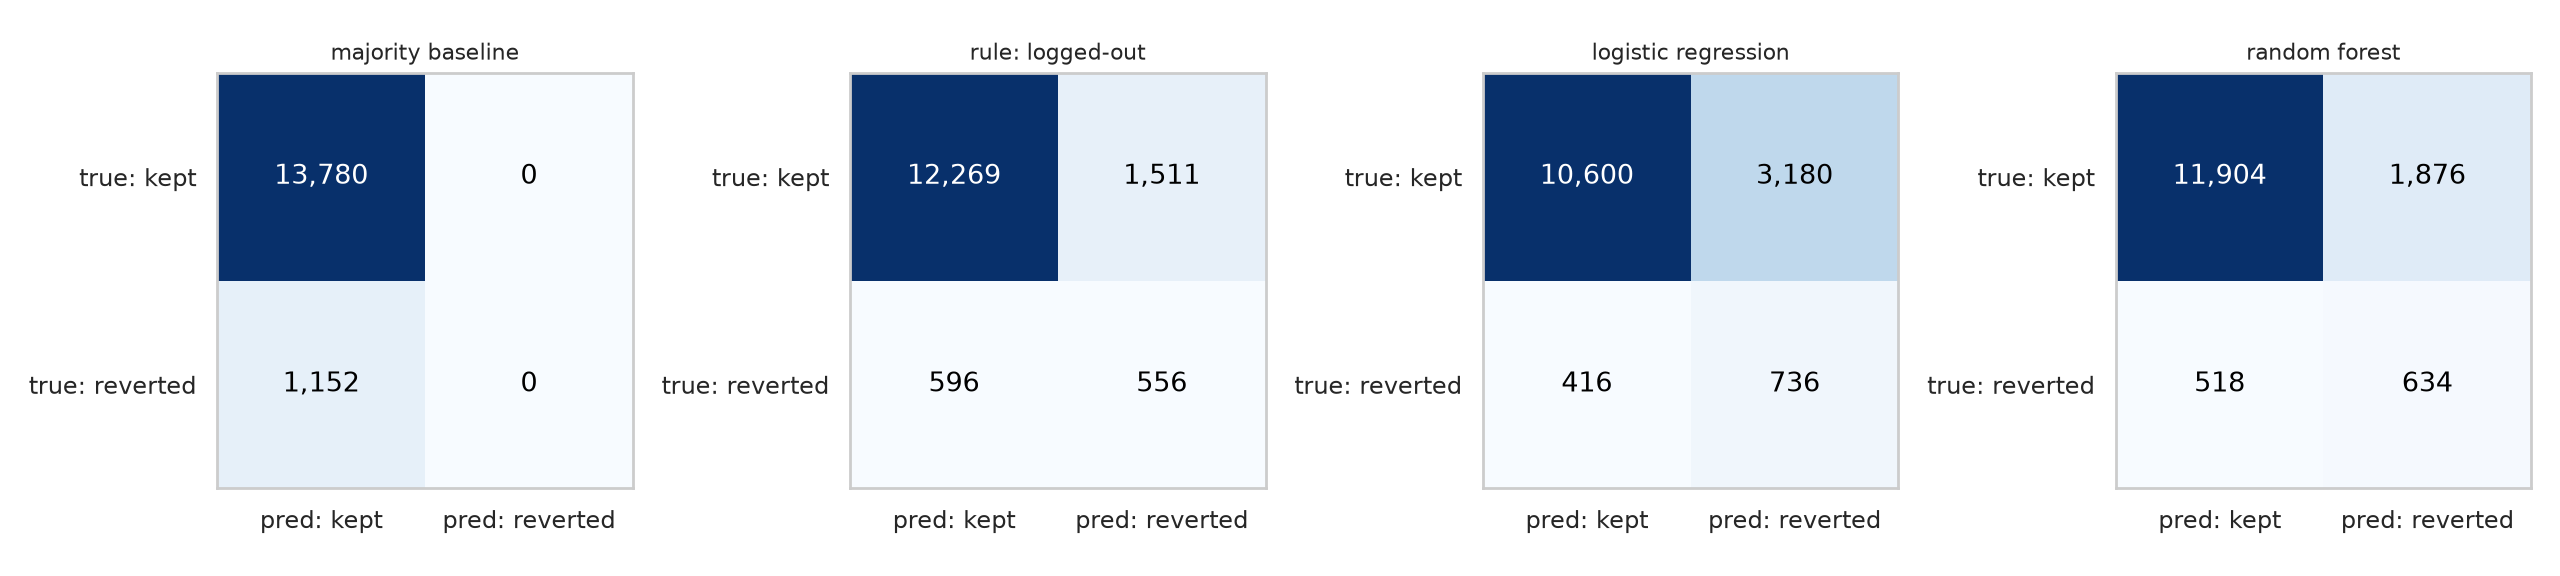

In [6]:
from src.ml.train import plot_confusions, plot_curves, FIG
FIG.mkdir(parents=True, exist_ok=True)
plot_confusions(results); display(Image(filename=str(FIG / "ml_confusion.png")))

## 5. ROC and precision–recall curves

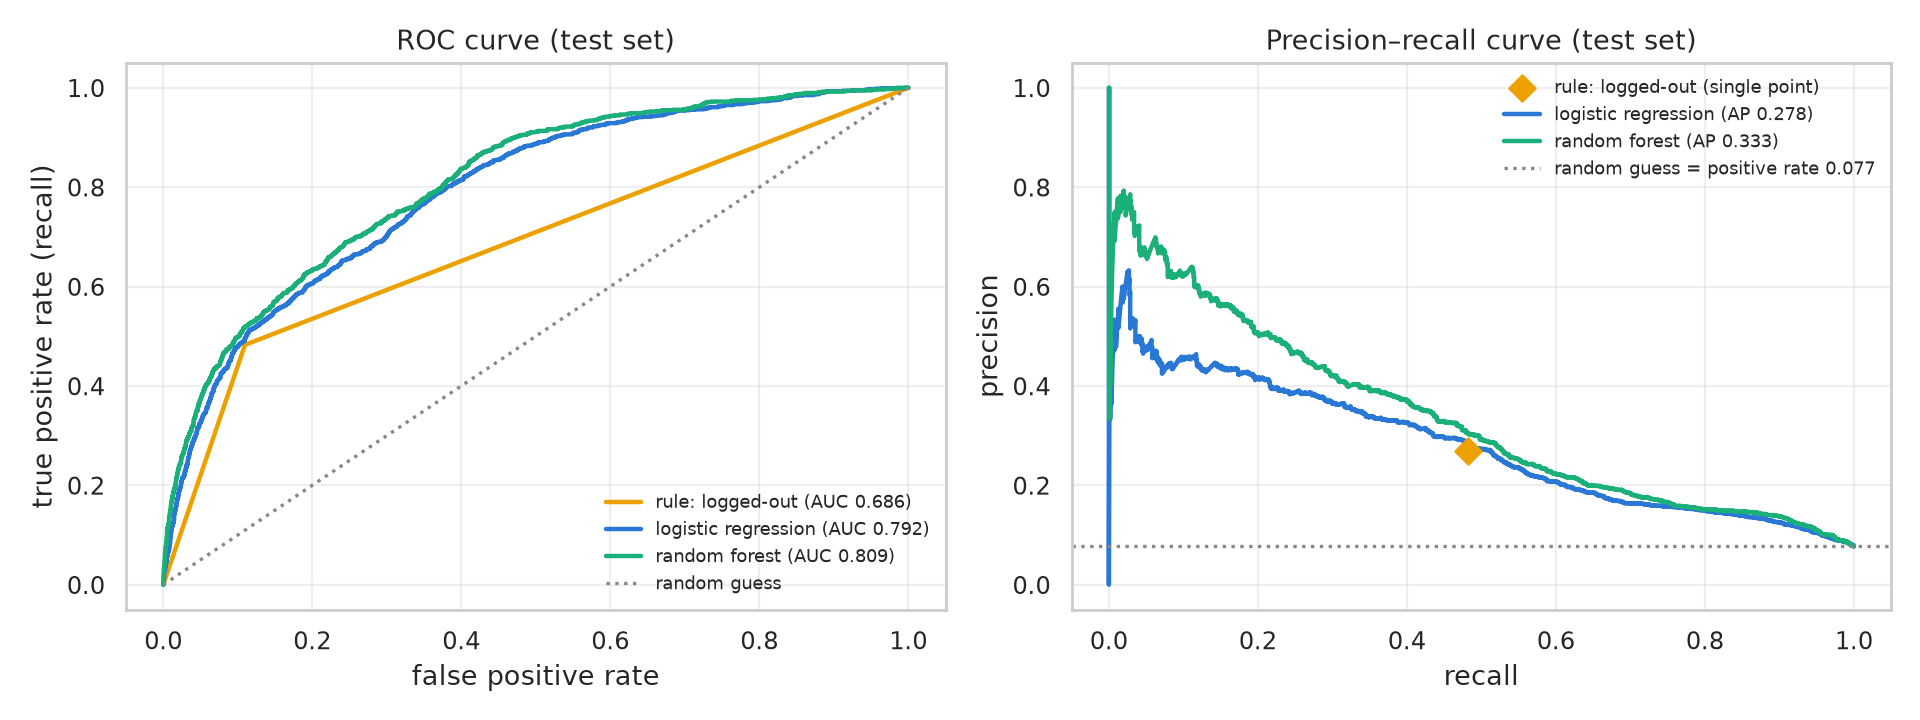

In [7]:
plot_curves(s, probas); display(Image(filename=str(FIG / "ml_roc_pr.png")))

## 6. A moderation view: "review the riskiest k % of edits"
Instead of one threshold, ask: if a patroller can only look at the top k % of edits ranked by the model, what share of
those are real reverts (precision) and what share of all reverts do they catch (recall)?

In [8]:
rows = []
y = s.y_test.to_numpy()
for name in ["rule: logged-out", "logistic regression", "random forest"]:
    order = np.argsort(-probas[name], kind="stable")
    for k in (1, 5, 10, 20):
        top = order[: int(len(y) * k / 100)]
        rows.append({"model": name, "review top %": k, "precision": y[top].mean(), "recall": y[top].sum() / y.sum()})
topk = pd.DataFrame(rows)
topk.pivot(index="review top %", columns="model", values=["precision", "recall"]).round(3)

precision                                             recall                               
model        logistic regression random forest rule: logged-out logistic regression random forest rule: logged-out
review top %                                                                                                      
1                          0.456         0.624            0.215               0.059         0.081            0.028
5                          0.387         0.437            0.271               0.251         0.283            0.175
10                         0.319         0.339            0.258               0.413         0.439            0.334
20                         0.220         0.228            0.197               0.569         0.592            0.511

Note: the rule gives every logged-out edit the same score, so its 'top k %' is an arbitrary subset of them.

## 7. Which features matter?

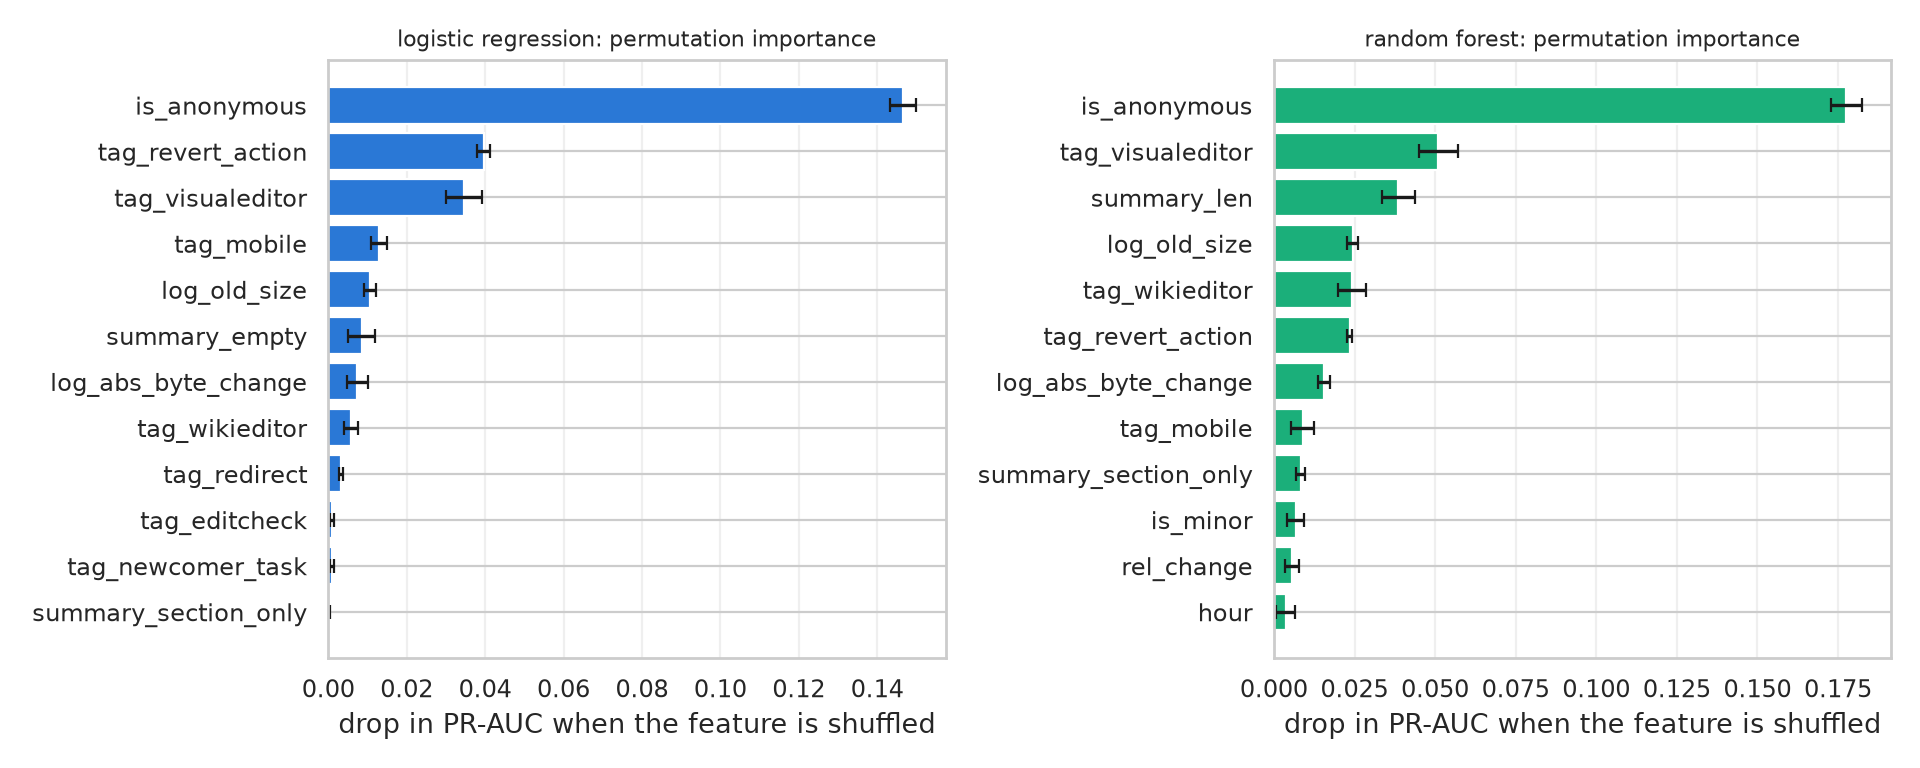

,LR coefficient (standardised)
bin__tag_tool,-0.921
time__hour_15,-0.520
time__hour_7,-0.494
bin__tag_newcomer_task,-0.432
time__weekday_3,-0.330
bin__tag_wikieditor,-0.324
time__weekday_4,-0.282
bin__tag_editcheck,-0.277
time__weekday_5,-0.252
time__hour_23,-0.210


In [9]:
from src.ml.train import importance, plot_importance
imp, coefs = importance(models, s)
plot_importance(imp); display(Image(filename=str(FIG / "ml_feature_importance.png")))
coefs.sort_values().round(3).to_frame("LR coefficient (standardised)")

Permutation importance = how much PR-AUC drops when one feature's values are shuffled on the test set.
LR coefficients: positive = pushes towards "reverted". Importance is **association**, not cause.

## 8. Save results

In [10]:
from src.config import EXPERIMENTS
results.to_csv(EXPERIMENTS / "metrics" / "ml_results.csv", index=False)
imp.to_csv(EXPERIMENTS / "metrics" / "ml_feature_importance.csv", index=False)
topk.to_csv(EXPERIMENTS / "metrics" / "ml_topk.csv", index=False)
coefs.sort_values().to_csv(EXPERIMENTS / "metrics" / "ml_lr_coefficients.csv", header=["coef"])
print("saved to experiments/metrics/ml_*.csv and reports/figures/ml_*.png")

saved to experiments/metrics/ml_*.csv and reports/figures/ml_*.png


## 9. Interpretation
- Positive rate in test: 7.71 %. Best model by PR-AUC: Random Forest, 0.333 (rule 0.170, random 0.077).
- At "review top 5 %": Random Forest precision 0.437, recall 0.283 (rule: 0.271 / 0.175).
- Top 1 %: precision 0.624 = 8x the base rate.
- Most important features: logged-out editor (by far), VisualEditor, edit is an undo/rollback,
  summary length, page size. Hour and weekday barely matter.
- The model beats the rule (about 2x PR-AUC). At a fixed 0.5 threshold the gain is small
  (F1 0.346 vs 0.345), so its value is in ranking edits for review, not in yes/no decisions.
- Accuracy is misleading: the "always kept" baseline has the highest accuracy (92.3 %) but finds no reverts.

## 10. Limitations
- Label noise: `mw-reverted` misses reverts MediaWiki did not detect; "0" means "no revert detected".
- No editor history (edit count, account age) — only what the recent-changes feed shows; real systems use much more.
- One month of data, one wiki, bots excluded; sample of 170 windows.
- Logged-out editors are temporary accounts since 2025 — results may not transfer to older data.
- Correlation, not causation; a flagged edit is not proven bad.